In this example, we combine **exponax** with [neojax](https://github.com/paulgekeler/neojax), a library for neural operators in JAX, to build a surrogate model that decides itself which simulations to run next.

Training data for neural operators is usually generated up front: we pick PDE parameters (often uniformly at random),
run the solver and train on whatever comes out. When the solver is cheap enough to call during training, we can instead
spend part of the simulation budget where the current model is weakest. We set up the experiment in two phases:

1. **Warm-up:** simulate a space-filling random design of PDE parameters and train an **ensemble** of Convolutional
   Neural Operators (CNOs) on it. While the model is still poor almost everywhere, uniform coverage is hard to beat, so
   active learning only takes over once the easy gains are realized.
2. **Targeted refinement:** in each round, draw a large pool of candidate inputs (PDE parameters *and* initial
   conditions), use the disagreement of the ensemble members to estimate the model's uncertainty on each of them,
   call the exponax solver for a batch of candidates sampled in proportion to their uncertainty, and fine-tune the
   ensemble on the enlarged dataset.

We compare this active learning loop against picking candidates from the same pool at random, on the same budget and
repeated over several random seeds.

Everything lives in JAX: exponax solvers are `equinox` modules, so we can `jax.vmap` a solver over PDE parameters, and
neojax models are `equinox` modules too, so an ensemble of five CNOs is just a single model `vmap`ped over its weights.

**GPU recommended**:
The solver is cheap, but training the CNO ensemble is not. The full configuration below takes about 30 minutes on an NVIDIA L4.
On a CPU, the gradients of the CNO's filtered activations (and of `vmap`ped convolutions) are slow in XLA, so training takes hours.
Use the smaller settings mentioned in the configuration cell to try it on a CPU.

In [ ]:
!pip3 install exponax "neojax-operators[ex]"

In [ ]:
import time

import equinox as eqx
import exponax as ex
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import optax

from neojax.metrics import RelativeLpMetric
from neojax.models import CNO

print(jax.devices())

[CudaDevice(id=0)]


#### Decaying Turbulence: the 2D Navier–Stokes Equations

We consider the incompressible Navier–Stokes equations in vorticity form on a periodic square $\Omega = (0, L)^2$:

$$
\partial_t \omega + (\mathbf{u} \cdot \nabla)\, \omega = \nu \Delta \omega,
\qquad \mathbf{u} = \nabla^\perp \psi, \qquad -\Delta \psi = \omega,
$$

where $\omega$ is the vorticity, $\mathbf{u}$ the velocity, $\psi$ the stream function and $\nu$ the viscosity. Without
forcing, the initial vortices swirl, merge and decay.

We vary two parameters: the viscosity $\nu$ (on a log scale) and the amplitude $A$ of the initial vorticity,
$\omega(\cdot, 0) = A\, s$, where $s$ is a random smooth field with $\max |s| = 1$. Together they set the Reynolds
number $\mathrm{Re} \propto A / \nu$, and with it the difficulty of the problem:

- at **low Reynolds numbers** (small $A$, large $\nu$), diffusion dominates and the solution is essentially a smoothed
  version of the initial condition, which is easy to learn;
- at **high Reynolds numbers** (large $A$, small $\nu$), the vortices are advected, stretched into thin filaments and
  transfer enstrophy to small scales within the time horizon, which is much harder.

The hard region is a corner of the parameter box, and the dynamics are still deterministic and smooth there over our
horizon (perturbing the initial condition by 0.1% changes the final state by at most a few tenths of a percent). This
is the setting where active learning should help: a small part of the input space is hard *and* learnable, and random
sampling spends most of its budget elsewhere.

Our surrogate learns the solution operator

$$
\mathcal{G}: \big(s, \log_{10} \nu, A\big) \mapsto \omega(\cdot, T) / A,
$$

i.e. it maps the shape of the initial condition and the parameters to the vorticity at a fixed final time $T$. We
measure the output in units of the initial amplitude, so that all targets have a similar scale.

#### Configuration

All settings of the experiment are collected in the next cell.

In [ ]:
# --- PDE and solver ---
N_POINTS = 64  # grid points per dimension (must be divisible by 2**CNO_LAYERS)
DOMAIN_EXTENT = 1.0  # side length L of the periodic domain
DT = 0.01  # solver time step
T_FINAL = 1.0  # final time T of the learned operator
LOG_NU_RANGE = (-4.0, -2.5)  # range of log10 viscosity
AMP_RANGE = (0.5, 10.0)  # range of the initial vorticity amplitude A
IC_CUTOFF = 4  # largest wavenumber of the random initial conditions
N_ICS_PER_PARAM = (
    4  # random initial conditions simulated per parameter pair in the warm-up
)

# --- Simulation budget ---
N_WARMUP_PARAMS = 32  # parameter pairs in the space-filling warm-up design
N_ROUNDS = 6  # refinement rounds
N_QUERY = 32  # simulations per round
CANDIDATE_GRID = (
    24  # candidate parameter pairs on a CANDIDATE_GRID x CANDIDATE_GRID grid ...
)
N_POOL_ICS = 4  # ... each with this many random initial conditions (the candidate pool)
ACQUISITION_POWER = 2.0  # queries are sampled with probability ~ uncertainty**power (0: random, large: greedy)

# --- Test set and repetitions ---
TEST_GRID = 16  # test parameters on a TEST_GRID x TEST_GRID grid
N_TEST_ICS = 4  # initial conditions per test parameter
N_SEEDS = 3  # independent repetitions of the whole experiment
GOOD_ERROR = 0.1  # threshold for the "fraction of accurate predictions" metric

# --- Ensemble and training ---
N_MEMBERS = 5  # ensemble size
CNO_LAYERS = 3
WARMUP_EPOCHS = 60  # epochs on the warm-up data
FINETUNE_EPOCHS = 30  # epochs on the full dataset after each acquisition
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
PREDICT_CHUNK = 128  # samples per forward pass when scoring candidates

# On a CPU, try e.g. N_POINTS = 32, CNO_LAYERS = 2, N_MEMBERS = 3, CANDIDATE_GRID = 12,
# TEST_GRID = 8, N_SEEDS = 1, WARMUP_EPOCHS = 20, FINETUNE_EPOCHS = 10.

P_LOW = jnp.array([LOG_NU_RANGE[0], AMP_RANGE[0]])
P_HIGH = jnp.array([LOG_NU_RANGE[1], AMP_RANGE[1]])
NU_LABEL, AMP_LABEL = r"$\log_{10} \nu$", "amplitude $A$"

#### Generating Data with exponax

An exponax stepper advances the state by one time step `DT` with an exponential time differencing Runge–Kutta (ETDRK)
method. `ex.repeat` turns it into a map from the initial state to the state at `T_FINAL`.

Because the stepper is an `equinox` module whose viscosity is an ordinary (traceable) field, we can construct it
*inside* a function and `jax.vmap` that function over the parameters. One jitted call therefore simulates an arbitrary
batch of different $(\nu, A)$ pairs in parallel.

The initial shapes $s$ are random truncated Fourier series (wavenumbers up to `IC_CUTOFF`) from exponax, normalized to a
maximum absolute value of one.

In [ ]:
ic_generator = ex.ic.RandomTruncatedFourierSeries(num_spatial_dims=2, cutoff=IC_CUTOFF)


def sample_initial_condition(key):
    s = ic_generator(N_POINTS, key=key)  # shape (1, N, N)
    return s / jnp.abs(s).max()


def solve(params, s):
    log_nu, amplitude = params
    stepper = ex.stepper.NavierStokesVorticity(
        num_spatial_dims=2,
        domain_extent=DOMAIN_EXTENT,
        num_points=N_POINTS,
        dt=DT,
        diffusivity=10.0**log_nu,
    )
    return ex.repeat(stepper, round(T_FINAL / DT))(amplitude * s) / amplitude


@jax.jit
def solve_batch(params, s):
    # params: (S, 2), s: (S, 1, N, N) -> solutions of shape (S, 1, N, N)
    return jax.vmap(solve)(params, s)


def sample_initial_conditions(key, n):
    return jax.vmap(sample_initial_condition)(jr.split(key, n))


def simulate(params, key):
    # params: (S, 2) -> random initial shapes and their solutions
    s = sample_initial_conditions(key, params.shape[0])
    return s, solve_batch(params, s)

The surrogate receives the parameters as two additional constant input channels, rescaled to $[0, 1]$.

- `acquire` simulates `N_ICS_PER_PARAM` random initial conditions for each requested parameter pair and returns model inputs and targets.
- `acquire_samples` simulates given pairs of initial conditions and parameters.

For the warm-up design we use a Latin hypercube. Each viscosity and each amplitude interval of width $1/n$ contains
exactly one sample, which covers the parameter box evenly.

In [ ]:
def normalize_params(params):
    return (params - P_LOW) / (P_HIGH - P_LOW)


def to_model_input(s, params):
    p = normalize_params(params)[:, :, None, None]
    p = jnp.broadcast_to(p, (params.shape[0], 2, N_POINTS, N_POINTS))
    return jnp.concatenate([s, p], axis=1)  # (S, 3, N, N)


def acquire(params, key):
    params = jnp.repeat(params, N_ICS_PER_PARAM, axis=0)
    s, y = simulate(params, key)
    return to_model_input(s, params), y, params


def acquire_samples(s, params):
    return to_model_input(s, params), solve_batch(params, s), params


def latin_hypercube_params(key, n):
    perm_key, jitter_key = jr.split(key)
    strata = jnp.stack([jr.permutation(k, n) for k in jr.split(perm_key, 2)], axis=1)
    return P_LOW + (P_HIGH - P_LOW) * (strata + jr.uniform(jitter_key, (n, 2))) / n


def param_grid(n):
    log_nu = jnp.linspace(*LOG_NU_RANGE, n)
    amp = jnp.linspace(*AMP_RANGE, n)
    nn, aa = jnp.meshgrid(
        log_nu, amp, indexing="xy"
    )  # rows: amplitude, columns: viscosity
    return jnp.stack([nn.ravel(), aa.ravel()], axis=-1)

Let us build the test set: a regular grid of parameters with `N_TEST_ICS` random initial conditions each.
We also time the solver.

In [ ]:
test_params = jnp.repeat(param_grid(TEST_GRID), N_TEST_ICS, axis=0)
start = time.perf_counter()
test_s, test_y = jax.block_until_ready(simulate(test_params, jr.key(1234)))
print(
    f"Simulated {len(test_params)} trajectories (incl. compilation) in {time.perf_counter() - start:.1f}s"
)

start = time.perf_counter()
jax.block_until_ready(simulate(test_params, jr.key(4321)))
print(
    f"Simulated {len(test_params)} trajectories in {time.perf_counter() - start:.1f}s"
)

test_x = to_model_input(test_s, test_params)

Simulated 1024 trajectories (incl. compilation) in 3.6s
Simulated 1024 trajectories in 0.5s


To get an overview of the dynamics, we tile the final vorticity of the first test initial condition for a coarse subset
of the test grid into a single image over the parameter plane (each tile scaled to its own maximum). At high viscosity or low amplitude, the solution is a
smoothed copy of the initial condition. Towards the upper left (high Reynolds number), the vortices are deformed and
thin filaments appear.

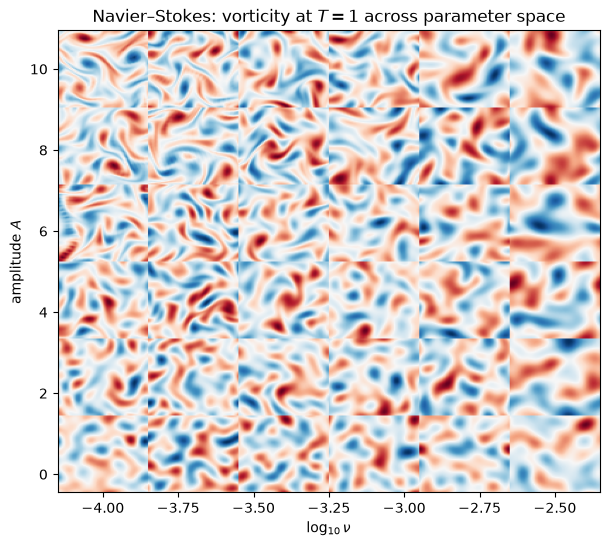

In [ ]:
def tile(fields, n):
    # (n*n, H, W) on the parameter grid -> one image with the amplitude increasing upwards
    h, w = fields.shape[-2:]
    img = fields.reshape(n, n, h, w)[::-1].transpose(0, 2, 1, 3).reshape(n * h, n * w)
    return np.asarray(img)


def grid_extent(n):
    # image extent so that the pixel centers of an n x n grid sit on the grid points
    dn, da = (
        (LOG_NU_RANGE[1] - LOG_NU_RANGE[0]) / (n - 1),
        (AMP_RANGE[1] - AMP_RANGE[0]) / (n - 1),
    )
    return (
        LOG_NU_RANGE[0] - dn / 2,
        LOG_NU_RANGE[1] + dn / 2,
        AMP_RANGE[0] - da / 2,
        AMP_RANGE[1] + da / 2,
    )


sub = np.arange(
    0, TEST_GRID, max(1, (TEST_GRID - 1) // 5)
)  # every few grid points along each axis
cells = (
    sub[:, None] * TEST_GRID + sub[None, :]
).ravel()  # rows: amplitude, columns: viscosity
fields = test_y[cells * N_TEST_ICS, 0]
fields = fields / jnp.abs(fields).max(axis=(-2, -1), keepdims=True)
log_nu_sub, amp_sub = (
    np.asarray(test_params[cells * N_TEST_ICS])
    .reshape(len(sub), len(sub), 2)
    .transpose(2, 0, 1)
)
dn, da = (log_nu_sub[0, 1] - log_nu_sub[0, 0]) / 2, (amp_sub[1, 0] - amp_sub[0, 0]) / 2
extent = (
    log_nu_sub.min() - dn,
    log_nu_sub.max() + dn,
    amp_sub.min() - da,
    amp_sub.max() + da,
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(
    tile(fields, len(sub)), extent=extent, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1
)
ax.set_xlabel(NU_LABEL)
ax.set_ylabel(AMP_LABEL)
ax.set_title(f"Navier–Stokes: vorticity at $T = {T_FINAL:g}$ across parameter space")
plt.show()

#### A CNO Ensemble with `vmap`

We use the Convolutional Neural Operator (CNO) from neojax as the surrogate. With `pad_mode="wrap"` all its
convolutions and filtered activations respect the periodic boundary conditions. Since the batch is small, we disable
batch normalization, which also keeps the model stateless.

To build an ensemble, we simply `eqx.filter_vmap` the model constructor over `N_MEMBERS` random keys. The result is a
single `CNO` whose arrays carry an additional leading *member* axis, while the static structure is shared. Every operation
on the ensemble (forward pass, loss, gradient, optimizer update) is then vectorized over the members.

In [ ]:
def make_cno(key):
    return CNO(
        key=key,
        in_channels=3,
        out_channels=1,
        ndim=2,
        n_layers=CNO_LAYERS,
        channel_multiplier=16,
        n_res_neck=2,
        latent_lift_proj_channels=32,
        batch_norm=False,
        pad_mode="wrap",
    )


def make_ensemble(key):
    return eqx.filter_vmap(make_cno)(jr.split(key, N_MEMBERS))


n_params = sum(
    x.size for x in jax.tree.leaves(eqx.filter(make_ensemble(jr.key(0)), eqx.is_array))
)
print(f"{N_MEMBERS} members with {n_params // N_MEMBERS:,} parameters each")

5 members with 367,345 parameters each


The ensemble prediction is a `vmap` over the members of a `vmap` over the batch. For scoring many candidates we feed the
samples in chunks to bound memory.

We evaluate the surrogate with the relative $L^2$ error of the ensemble mean. To make the uncertainty comparable to this
error, we measure it in the same way: the ensemble spread (the root of the summed variance over all grid points)
relative to the norm of the mean prediction. Without this normalization, samples with large field values would always
look more uncertain.

In [ ]:
@eqx.filter_jit
def ensemble_predict(ensemble, x):
    return eqx.filter_vmap(lambda model: jax.vmap(model)(x))(
        ensemble
    )  # (E, B, 1, N, N)


def predict_in_chunks(ensemble, x):
    preds = [
        ensemble_predict(ensemble, x[i : i + PREDICT_CHUNK])
        for i in range(0, len(x), PREDICT_CHUNK)
    ]
    return jnp.concatenate(preds, axis=1)


def relative_l2(pred, target):
    # ensemble aware relative l2 error
    axes = tuple(range(1, target.ndim))
    return jnp.sqrt(jnp.sum((pred - target) ** 2, axes) / jnp.sum(target**2, axes))


def relative_uncertainty(preds):
    mean = preds.mean(axis=0)
    axes = tuple(range(1, mean.ndim))
    return jnp.sqrt(preds.var(axis=0).sum(axes) / jnp.sum(mean**2, axes))

#### Training

Each member is trained with the relative $L^2$ loss from neojax on its own bootstrapped mini-batches: we draw an
index array of shape `(N_MEMBERS, BATCH_SIZE)`, so indexing the dataset directly yields one batch per member. Summing the
member losses gives a scalar whose gradient w.r.t. each member's weights is just that member's gradient, so a single
Adam optimizer trains all members independently.

The number of steps scales with the dataset size (a fixed number of epochs), so a larger dataset is not underfit. Every
call to `train` restarts a cosine learning rate schedule. We pass the learning rate into the jitted step as an array, so
schedules of different lengths do not trigger recompilation.

In [ ]:
rel_l2_loss = RelativeLpMetric(p=2)
adam = optax.scale_by_adam()


def member_loss(model, x, y):
    return rel_l2_loss(target=y, pred=jax.vmap(model)(x))


def ensemble_loss(ensemble, xb, yb):
    losses = eqx.filter_vmap(member_loss)(ensemble, xb, yb)
    return losses.sum(), losses


@eqx.filter_jit
def train_step(ensemble, opt_state, xb, yb, lr):
    (_, losses), grads = eqx.filter_value_and_grad(ensemble_loss, has_aux=True)(
        ensemble, xb, yb
    )
    updates, opt_state = adam.update(grads, opt_state)
    updates = jax.tree.map(lambda u: -lr * u, updates)
    return eqx.apply_updates(ensemble, updates), opt_state, losses


def train(ensemble, x, y, key, epochs):
    n_steps = max(1, epochs * len(x) // BATCH_SIZE)
    schedule = optax.cosine_decay_schedule(LEARNING_RATE, n_steps, alpha=0.05)
    opt_state = adam.init(eqx.filter(ensemble, eqx.is_array))
    for step in range(n_steps):
        key, subkey = jr.split(key)
        idx = jr.randint(subkey, (N_MEMBERS, BATCH_SIZE), 0, x.shape[0])
        ensemble, opt_state, losses = train_step(
            ensemble, opt_state, x[idx], y[idx], schedule(step)
        )
    return ensemble, losses

#### Choosing the Next Simulations

The model input consists of the initial condition *and* the parameters, and both affect how hard a sample is. We
therefore score complete inputs. A candidate pool of every parameter pair of a `CANDIDATE_GRID` x `CANDIDATE_GRID`
grid with `N_POOL_ICS` random initial conditions each, and later simulate exactly the chosen candidates. Scoring the pool
does not need the solver, only a forward pass of the ensemble.

Which candidates should we simulate? Taking the `N_QUERY` most uncertain ones (greedy top-k) sounds natural but tends
to work poorly. The top scores sit next to each other, so a whole batch lands in one small region, and if the model
cannot fit that region yet, the batch is wasted. Instead we use *stochastic batch acquisition*
([Kirsch et al., *Stochastic Batch Acquisition*, TMLR 2023](https://arxiv.org/abs/2106.12059)): we sample `N_QUERY`
candidates without replacement with probability proportional to $\text{uncertainty}^{\beta}$, with
$\beta$ = `ACQUISITION_POWER`. Uncertain regions still get most of the budget, but batches stay spread out. A neat way to
sample without replacement is the Gumbel-top-k trick (add Gumbel noise to the log-weights and take the top k).

The power $\beta$ sets how focused the batches are. Here the uncertainty varies by about one order of magnitude across
the pool, and with $\beta = 1$ the many moderately uncertain candidates together still draw most of the queries, so the
batches look almost uniform. With $\beta = 2$, the most uncertain candidates are about 100 times more likely to be
picked than the most certain ones, which concentrates the budget in the high Reynolds number corner.

The random baseline picks `N_QUERY` candidates from the same pool uniformly at random, i.e. $\beta = 0$.

In [ ]:
candidates = param_grid(CANDIDATE_GRID)


def candidate_pool(key):
    # every candidate parameter pair with N_POOL_ICS random initial conditions
    params = jnp.repeat(candidates, N_POOL_ICS, axis=0)
    return sample_initial_conditions(key, len(params)), params


def score_pool(ensemble, s, params):
    return relative_uncertainty(predict_in_chunks(ensemble, to_model_input(s, params)))


def sample_by_uncertainty(key, scores, k, power=ACQUISITION_POWER):
    # Gumbel-top-k: k samples without replacement with probabilities ~ scores**power
    logits = power * jnp.log(scores) + jr.gumbel(key, scores.shape)
    return np.asarray(jax.lax.top_k(logits, k)[1])

#### Warm-up and Refinement

`warm_up` simulates the Latin hypercube design and trains a fresh ensemble on it. Both strategies then start from this
same ensemble and dataset. In every round, `run_campaign` draws a candidate pool (the same one for both strategies)
and simulates either candidates sampled by uncertainty or random candidates. Everything else (number of simulations,
training schedule, keys) is identical. After every step we record the test error of the ensemble mean, its relative
uncertainty and the simulated parameters.

In [ ]:
def evaluate(ensemble):
    preds = predict_in_chunks(ensemble, test_x)
    return relative_l2(preds.mean(axis=0), test_y), relative_uncertainty(preds)


def log(name, record, losses, train_time, solve_time):
    print(
        f"[{name:>6s}] simulations {record['n_sims']:4d} | train loss {losses.mean():.3f} "
        f"| test rel. L2 mean {record['test_errors'].mean():.3f} median {jnp.median(record['test_errors']):.3f} "
        f"| train {train_time:5.1f}s | solver {solve_time:4.2f}s"
    )


def warm_up(key):
    design_key, ic_key, model_key, train_key = jr.split(key, 4)
    x, y, params = acquire(latin_hypercube_params(design_key, N_WARMUP_PARAMS), ic_key)
    start = time.perf_counter()
    ensemble, losses = train(make_ensemble(model_key), x, y, train_key, WARMUP_EPOCHS)
    train_time = time.perf_counter() - start
    errors, stds = evaluate(ensemble)
    record = dict(n_sims=len(x), params=params, test_errors=errors, test_stds=stds)
    log("warmup", record, losses, train_time, 0.0)
    return ensemble, x, y, params, record


def run_campaign(strategy, warm, key):
    ensemble, x, y, params, warm_record = warm
    history = [warm_record]
    for _ in range(N_ROUNDS):
        key, pool_key, pick_key, train_key = jr.split(key, 4)
        record = dict(params_before=params)
        pool_s, pool_params = candidate_pool(pool_key)
        if strategy == "active":
            scores = score_pool(ensemble, pool_s, pool_params)
            idx = sample_by_uncertainty(pick_key, scores, N_QUERY)
            record["scores"] = scores
        else:
            idx = np.asarray(
                jr.choice(pick_key, len(pool_params), (N_QUERY,), replace=False)
            )

        start = time.perf_counter()
        x_new, y_new, p_new = jax.block_until_ready(
            acquire_samples(pool_s[idx], pool_params[idx])
        )
        solve_time = time.perf_counter() - start
        x, y = jnp.concatenate([x, x_new]), jnp.concatenate([y, y_new])
        params = jnp.concatenate([params, p_new])

        start = time.perf_counter()
        ensemble, losses = train(ensemble, x, y, train_key, FINETUNE_EPOCHS)
        train_time = time.perf_counter() - start

        errors, stds = evaluate(ensemble)
        record.update(
            n_sims=len(x),
            params=params,
            queried=p_new,
            test_errors=errors,
            test_stds=stds,
        )
        history.append(record)
        log(strategy, record, losses, train_time, solve_time)
    return ensemble, history

Now we run the experiment for `N_SEEDS` seeds. Each seed has its own warm-up design, initialization and test-time
randomness, and both strategies share the warm-up of their seed. Note how the solver time is negligible compared to
training: with exponax, querying new data is essentially free, which is exactly the setting where solver-in-the-loop
training is practical.

In [ ]:
strategies = ("active", "random")
histories = {s: [] for s in strategies}
final_ensembles = {}  # ensembles of the first seed, for plotting predictions

for seed in range(N_SEEDS):
    print(f"--- seed {seed} ---")
    warm_key, campaign_key = jr.split(jr.key(seed))
    warm = warm_up(warm_key)
    for strategy in strategies:
        ensemble, history = run_campaign(strategy, warm, campaign_key)
        histories[strategy].append(history)
        if seed == 0:
            final_ensembles[strategy] = ensemble

--- seed 0 ---
[warmup] simulations  128 | train loss 0.152 | test rel. L2 mean 0.189 median 0.138 | train  63.5s | solver 0.00s
[active] simulations  160 | train loss 0.154 | test rel. L2 mean 0.163 median 0.116 | train  29.4s | solver 0.03s
[active] simulations  192 | train loss 0.150 | test rel. L2 mean 0.141 median 0.097 | train  34.9s | solver 0.03s
[active] simulations  224 | train loss 0.133 | test rel. L2 mean 0.125 median 0.083 | train  40.9s | solver 0.03s
[active] simulations  256 | train loss 0.133 | test rel. L2 mean 0.112 median 0.074 | train  46.4s | solver 0.03s
[active] simulations  288 | train loss 0.114 | test rel. L2 mean 0.102 median 0.066 | train  52.4s | solver 0.03s
[active] simulations  320 | train loss 0.102 | test rel. L2 mean 0.095 median 0.062 | train  58.2s | solver 0.03s
[random] simulations  160 | train loss 0.151 | test rel. L2 mean 0.165 median 0.115 | train  29.0s | solver 0.03s
[random] simulations  192 | train loss 0.124 | test rel. L2 mean 0.147 me

#### Results

First, the learning curves over the number of simulations, averaged over the seeds (the shaded band spans the best and
worst seed). We look at three summaries of the test errors, since they can tell different stories:

- the **mean** is dominated by the hardest samples,
- the **median** describes the typical sample,
- the **fraction of accurate predictions** counts the test samples with a relative error below `GOOD_ERROR`.

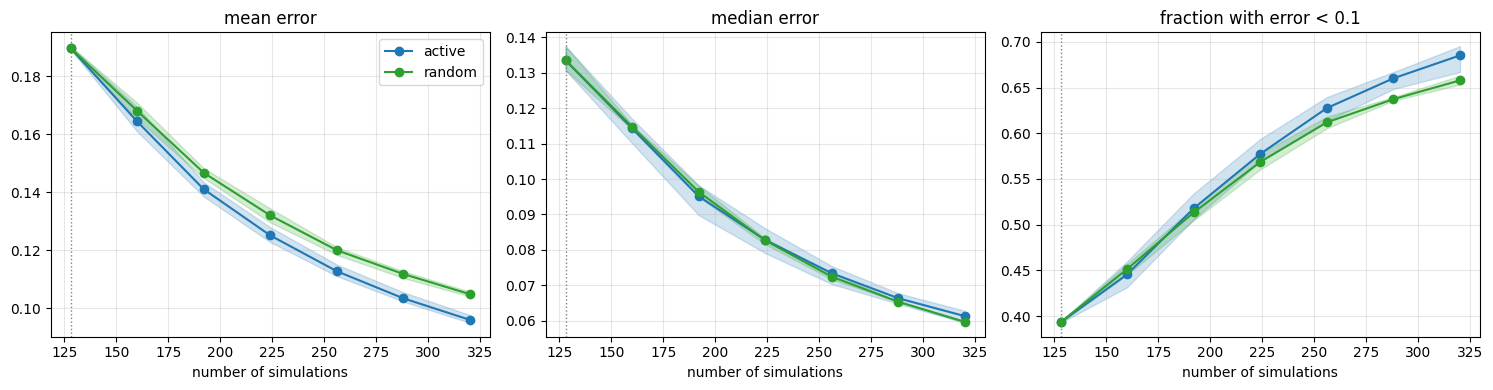

active (final): mean error 0.096 ± 0.001, median error 0.061 ± 0.001, fraction with error < 0.1 0.685 ± 0.013
random (final): mean error 0.105 ± 0.001, median error 0.060 ± 0.000, fraction with error < 0.1 0.658 ± 0.004


In [ ]:
n_sims = [h["n_sims"] for h in histories["active"][0]]
errors = {
    s: np.stack([[np.asarray(h["test_errors"]) for h in hist] for hist in histories[s]])
    for s in strategies
}
metrics = {
    "mean error": lambda e: e.mean(-1),
    "median error": lambda e: np.median(e, -1),
    f"fraction with error < {GOOD_ERROR}": lambda e: (e < GOOD_ERROR).mean(-1),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, metric) in zip(axes, metrics.items(), strict=True):
    for strategy, color in zip(strategies, ("C0", "C2"), strict=True):
        values = metric(errors[strategy])  # (seeds, steps)
        ax.plot(n_sims, values.mean(0), "o-", color=color, label=strategy)
        ax.fill_between(n_sims, values.min(0), values.max(0), color=color, alpha=0.2)
    ax.axvline(n_sims[0], color="gray", ls=":", lw=1)
    ax.set_title(title)
    ax.set_xlabel("number of simulations")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

for strategy in strategies:
    summary = ", ".join(
        f"{title} {metric(errors[strategy][:, -1]).mean():.3f} ± {metric(errors[strategy][:, -1]).std():.3f}"
        for title, metric in metrics.items()
    )
    print(f"{strategy:>6s} (final): {summary}")

The spread between seeds can be larger than the difference between the strategies, since each seed has its own warm-up
design and initialization. Within a seed, however, both strategies share the warm-up, the candidate pools and the
training keys, so the paired difference (active minus random, per seed) isolates the effect of the acquisition
strategy. Below zero means active learning has the lower error (or, for the last panel, the lower fraction of
accurate predictions, so there *above* zero is better).

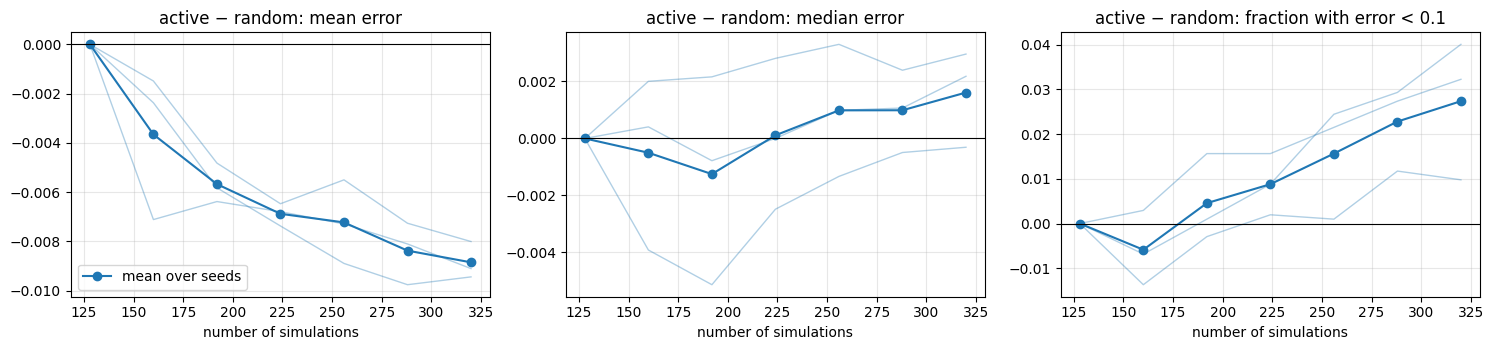

mean error: active learning is better in 3 of 3 seeds (paired difference -0.0088)
median error: active learning is better in 1 of 3 seeds (paired difference +0.0016)
fraction with error < 0.1: active learning is better in 3 of 3 seeds (paired difference +0.0273)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (title, metric) in zip(axes, metrics.items(), strict=True):
    paired = metric(errors["active"]) - metric(errors["random"])  # (seeds, steps)
    for seed_diff in paired:
        ax.plot(n_sims, seed_diff, color="C0", alpha=0.35, lw=1)
    ax.plot(n_sims, paired.mean(0), "o-", color="C0", label="mean over seeds")
    ax.axhline(0.0, color="k", lw=0.8)
    ax.set_title(f"active − random: {title}")
    ax.set_xlabel("number of simulations")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

for title, metric in metrics.items():
    final = metric(errors["active"][:, -1]) - metric(errors["random"][:, -1])
    wins = (final > 0).sum() if title.startswith("fraction") else (final < 0).sum()
    print(
        f"{title}: active learning is better in {wins} of {N_SEEDS} seeds (paired difference {final.mean():+.4f})"
    )

Where did the active learner query the solver? For the first seed, the panels show the relative uncertainty at the
start of each round (averaged over the initial conditions of each candidate), the training data so far (white) and the
queried candidates (cyan crosses).

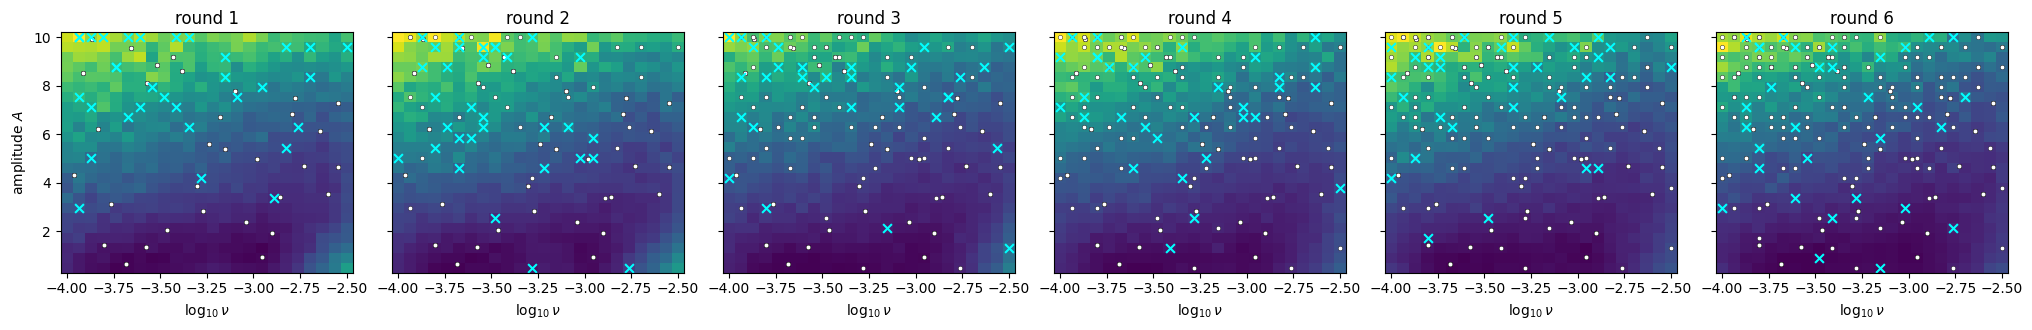

In [ ]:
rounds = histories["active"][0][1:]
fig, axes = plt.subplots(1, len(rounds), figsize=(3.4 * len(rounds), 3.4), sharey=True)
for i, (ax, h) in enumerate(zip(np.atleast_1d(axes), rounds, strict=True)):
    ax.imshow(
        np.asarray(h["scores"])
        .reshape(CANDIDATE_GRID, CANDIDATE_GRID, N_POOL_ICS)
        .mean(-1)[::-1],
        extent=grid_extent(CANDIDATE_GRID),
        aspect="auto",
        cmap="viridis",
    )
    ax.scatter(
        *np.asarray(h["params_before"]).T,
        s=10,
        c="white",
        edgecolors="k",
        linewidths=0.3,
    )
    ax.scatter(*np.asarray(h["queried"]).T, s=40, c="cyan", marker="x")
    ax.set_title(f"round {i + 1}")
    ax.set_xlabel(NU_LABEL)
np.atleast_1d(axes)[0].set_ylabel(AMP_LABEL)
plt.tight_layout()
plt.show()

The final error over parameter space for both strategies, averaged over the test initial conditions and the seeds, and
the difference between them (blue: active learning is better, red: random sampling is better). The white dots are the
parameters simulated in the first seed.

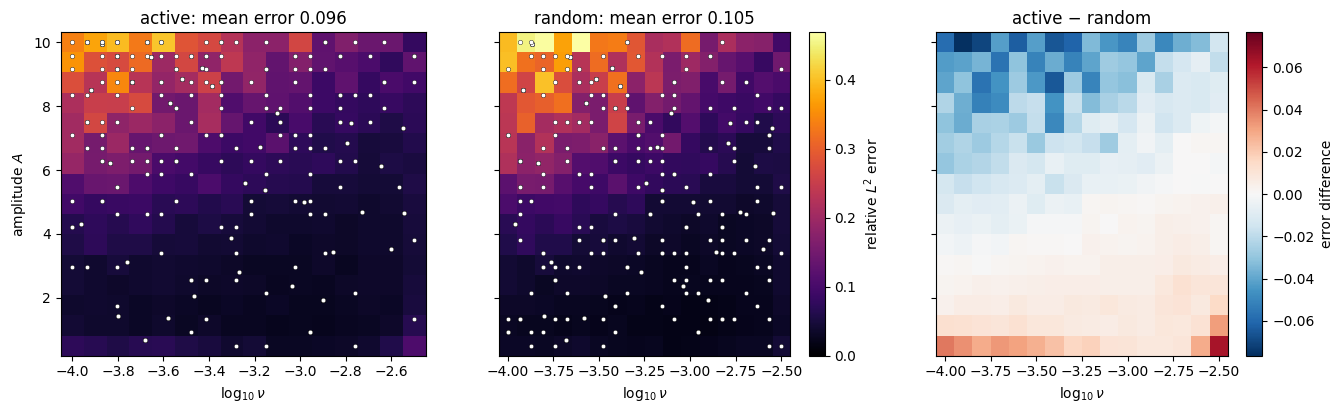

In [ ]:
def error_map(errors):
    # (..., n_test) -> mean over leading axes and test initial conditions, as an image with the amplitude upwards
    e = (
        np.asarray(errors)
        .reshape(-1, TEST_GRID * TEST_GRID, N_TEST_ICS)
        .mean(axis=(0, 2))
    )
    return e.reshape(TEST_GRID, TEST_GRID)[::-1]


maps = {s: error_map(errors[s][:, -1]) for s in strategies}
vmax = max(float(m.max()) for m in maps.values())
diff = maps["active"] - maps["random"]
dmax = float(np.abs(diff).max())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, strategy in zip(axes[:2], strategies, strict=True):
    im = ax.imshow(
        maps[strategy],
        extent=grid_extent(TEST_GRID),
        aspect="auto",
        cmap="inferno",
        vmin=0,
        vmax=vmax,
    )
    ax.scatter(
        *np.asarray(histories[strategy][0][-1]["params"]).T,
        s=10,
        c="white",
        edgecolors="k",
        linewidths=0.3,
    )
    ax.set_title(f"{strategy}: mean error {maps[strategy].mean():.3f}")
    ax.set_xlabel(NU_LABEL)
fig.colorbar(im, ax=axes[1], label="relative $L^2$ error")
im = axes[2].imshow(
    diff,
    extent=grid_extent(TEST_GRID),
    aspect="auto",
    cmap="RdBu_r",
    vmin=-dmax,
    vmax=dmax,
)
axes[2].set_title("active − random")
axes[2].set_xlabel(NU_LABEL)
fig.colorbar(im, ax=axes[2], label="error difference")
axes[0].set_ylabel(AMP_LABEL)
plt.show()

How useful is the ensemble disagreement as a proxy for the error? On the test set we know the true error, so we can
check whether the uncertainty ranks the samples similarly to the error (Spearman rank correlation). Points in the upper
left are samples where the ensemble is confidently wrong: the members agree, but on the wrong answer. Uncertainty-driven
sampling cannot find these samples; if they dominated, mixing some random queries into each batch would help.

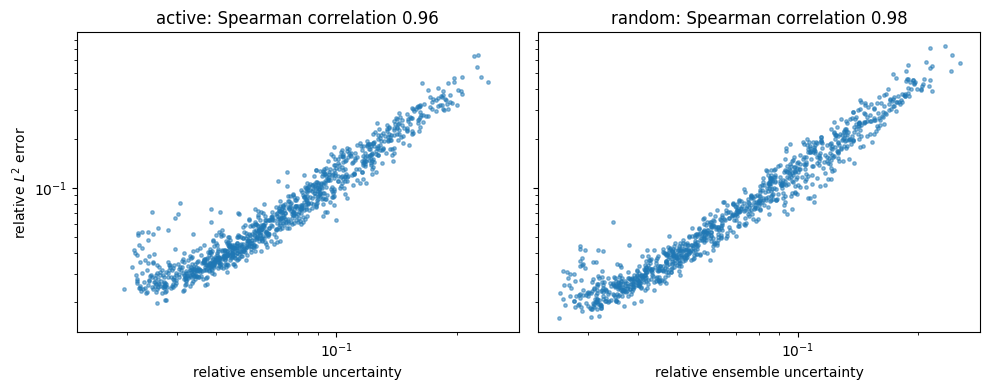

In [ ]:
def spearman(a, b):
    ranks_a = jnp.argsort(jnp.argsort(a))
    ranks_b = jnp.argsort(jnp.argsort(b))
    return jnp.corrcoef(ranks_a, ranks_b)[0, 1]


fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, strategy in zip(axes, strategies, strict=True):
    h = histories[strategy][0][-1]
    ax.scatter(h["test_stds"], h["test_errors"], s=6, alpha=0.5)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("relative ensemble uncertainty")
    ax.set_title(
        f"{strategy}: Spearman correlation {spearman(h['test_stds'], h['test_errors']):.2f}"
    )
axes[0].set_ylabel("relative $L^2$ error")
plt.tight_layout()
plt.show()

Finally, predictions of both ensembles (first seed) for the test samples where active learning improved most over random
sampling and where it was worst, together with the ensemble standard deviation. Each row shares one color scale for the
vorticity fields and one for the standard deviations.

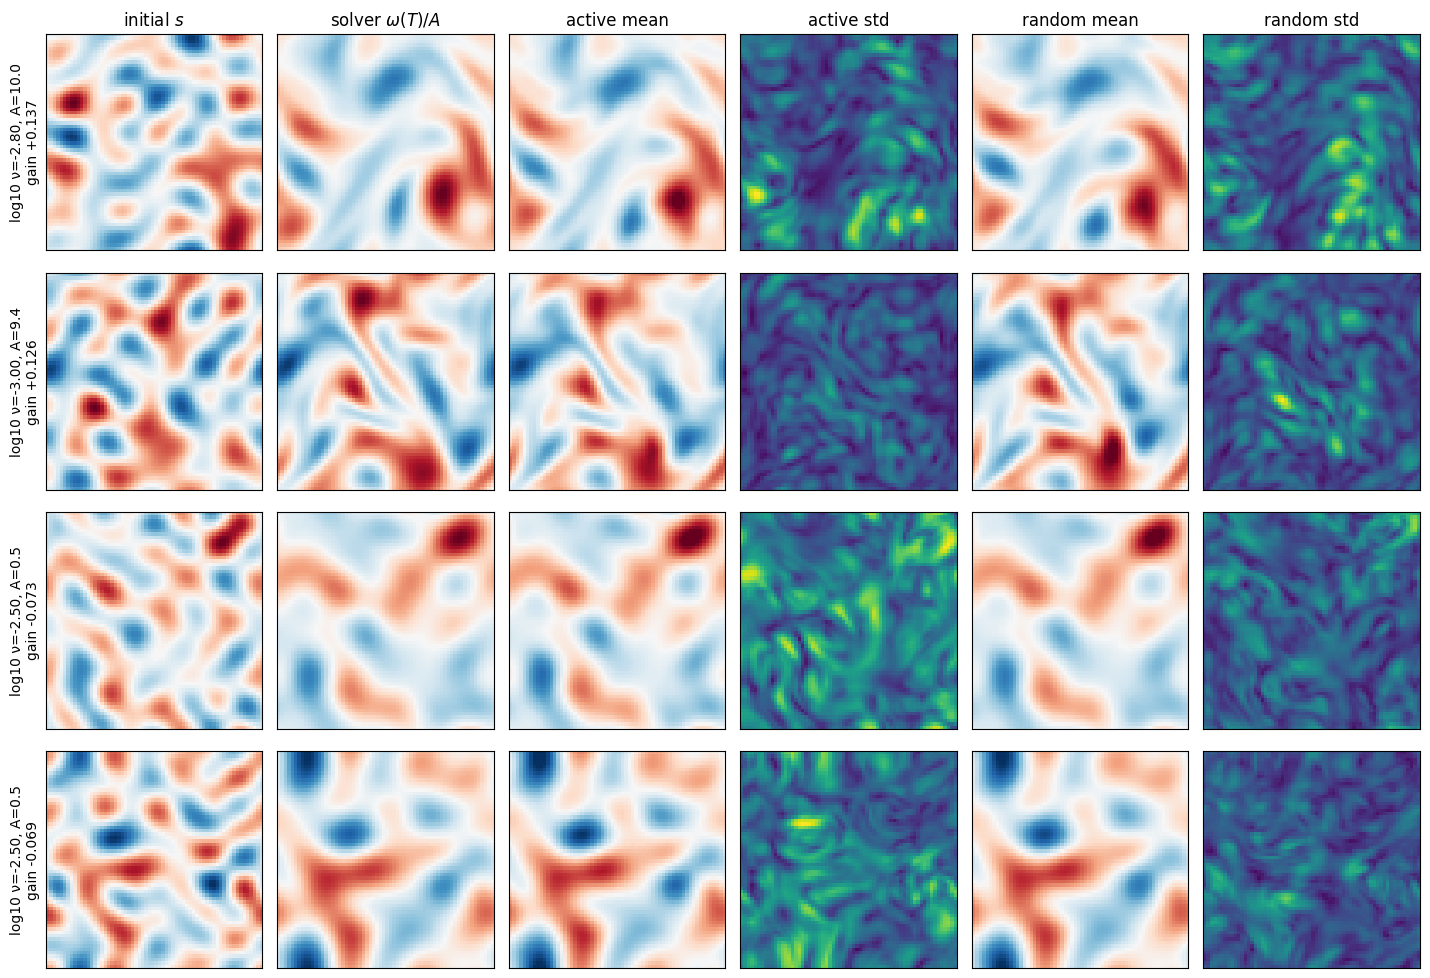

In [ ]:
gain = np.asarray(
    histories["random"][0][-1]["test_errors"]
    - histories["active"][0][-1]["test_errors"]
)
idx = np.concatenate([np.argsort(-gain)[:2], np.argsort(gain)[:2]])
active_preds = ensemble_predict(final_ensembles["active"], test_x[idx])[:, :, 0]
random_preds = ensemble_predict(final_ensembles["random"], test_x[idx])[:, :, 0]

columns = [
    ("initial $s$", test_x[idx, 0]),
    (r"solver $\omega(T) / A$", test_y[idx, 0]),
    ("active mean", active_preds.mean(0)),
    ("active std", active_preds.std(0)),
    ("random mean", random_preds.mean(0)),
    ("random std", random_preds.std(0)),
]
fig, axes = plt.subplots(
    len(idx), len(columns), figsize=(2.4 * len(columns), 2.5 * len(idx))
)
for row, i in enumerate(idx):
    vmax = float(jnp.abs(test_y[i]).max())
    std_max = float(max(columns[3][1][row].max(), columns[5][1][row].max()))
    for col, (title, fields) in enumerate(columns):
        ax = axes[row, col]
        if "std" in title:
            ax.imshow(fields[row], cmap="viridis", vmin=0, vmax=std_max)
        else:
            scale = 1.0 if col == 0 else vmax
            ax.imshow(fields[row], cmap="RdBu_r", vmin=-scale, vmax=scale)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(title)
    log_nu, amp = test_params[i]
    axes[row, 0].set_ylabel(f"log10 ν={log_nu:.2f}, A={amp:.1f}\ngain {gain[i]:+.3f}")
plt.tight_layout()
plt.show()

#### Discussion

In our run on an NVIDIA L4 (three seeds, the configuration above), active learning was consistently ahead:

- After 320 simulations, the mean test error is $0.096 \pm 0.001$ with active learning and $0.105 \pm 0.001$ with random
  sampling, lower in all three seeds (paired difference $-0.009$, about 8%). Active learning reaches the final error of
  random sampling after roughly 280 simulations, i.e. it saves about 40 of the 192 simulations of the refinement phase.
- The fraction of test samples with an error below 0.1 rises to 68.5% versus 65.8%, again in all three seeds.
- The median error is the same for both (about 0.06): the typical test sample lies in the easy, low Reynolds number
  part of the parameter box, which both strategies cover well.
- The gap grows with every round. The paired differences start at zero after the shared warm-up and keep widening, so
  the advantage comes from the acquisition and is not a lucky seed.

The error maps show where the gain comes from: the difference is strongly negative (up to about $-0.07$) in the high
Reynolds number corner, where the queries concentrate. It is positive at the smallest amplitudes, which active learning
samples less, most strongly at the highest viscosity. In both strategies the final ensemble’s uncertainty ranks its own
test errors almost perfectly (Spearman correlation 0.96 for active, 0.98 for random), so the uncertainty is a reliable
stand-in for the error, which is what the acquisition relies on. The slightly lower value for active learning is expected:
it removes the largest errors, which leaves a narrower spread of errors that is harder to rank.

Two settings mattered. With `ACQUISITION_POWER = 1`, the queries were close to uniform and the gain was about a quarter
smaller (a paired difference of $-0.007$ instead of $-0.009$ after 320 simulations); $\beta = 2$ concentrates them in
the hard corner. More refinement rounds also helped: the advantage keeps
growing as the overall error drops.

#### Summary

- Active learning beat random sampling in every seed: about 8% lower final error, or roughly 40 fewer simulations for
  the same error, because the ensemble uncertainty reliably points at the small, hard high Reynolds number corner.
- It needs a space-filling warm-up, stochastic acquisition (greedy top-k would crowd each batch into the hardest spot)
  and a hard region that is small and learnable. In an earlier Gray–Scott version of this example, the hard region was
  large and depended sharply on the initial condition, and random sampling did just as well.
- **exponax** and **neojax** fit together naturally: both are built on `equinox`, so a batch of simulations with different
  parameters is one `vmap`ped, jitted solver call, and an ensemble of neojax models is one model with a member axis.
  Data generation, training and acquisition live in a single JAX program, with no data files or framework boundaries in
  between.

Possible extensions: better calibrated uncertainty (e.g. more diverse ensemble members or a learned error predictor),
other exponax PDEs (e.g. `ex.stepper.KolmogorovFlowVorticity` for forced turbulence or `ex.stepper.KuramotoSivashinsky`),
more parameters (e.g. a drag coefficient), or autoregressive surrogates trained on full trajectories.